# AISTER: one painting through the pipeline

The workflow of the AISTER crowdsourcing pilot, applied to a single painting from the Europeana gallery [Ukrainian folk art](https://www.europeana.eu/en/galleries/26106-ukrainian-folk-art). The code, models and prompts are those of the published notebooks in [Web2LearnEU/AISTER-Crowdsourcing-Pilot](https://github.com/Web2LearnEU/AISTER-Crowdsourcing-Pilot).

## Setup
Libraries, the Europeana API key, and the locations of the pilot’s published results on GitHub.

The record and image of each painting come from the Europeana APIs: the Search API returns the full record of an item (title, description, subject terms, places, creator, rights and the link to the image). Requests need a free API key, which you can request with a free Europeana account at europeana.eu/account/api-keys. The notebook reads it from Colab Secrets as EUROPEANA_API_KEY.

In [2]:
!pip install -q -U "transformers>=5.2.0" accelerate "pillow<12" matplotlib spacy openpyxl
!python -m spacy download en_core_web_sm -q

In [3]:
import json
import os
import re
import time
import textwrap
import unicodedata
import xml.etree.ElementTree as ET
from datetime import datetime, timezone
from io import BytesIO
from urllib.parse import quote

import matplotlib.pyplot as plt
import pandas as pd
import requests
import spacy
import torch
from IPython.display import display
from PIL import Image
from transformers import (AutoModelForCausalLM, AutoProcessor, AutoTokenizer,
                          Qwen3VLForConditionalGeneration)

try:
    from google.colab import userdata
except ImportError:
    userdata = None

if userdata is not None:
    EUROPEANA_API_KEY = userdata.get('EUROPEANA_API_KEY')
else:
    EUROPEANA_API_KEY = os.environ.get('EUROPEANA_API_KEY')

if not EUROPEANA_API_KEY:
    raise ValueError('EUROPEANA_API_KEY not found.')

HEADERS = {"X-API-KEY": EUROPEANA_API_KEY}
REPO_RAW = "https://raw.githubusercontent.com/Web2LearnEU/AISTER-Crowdsourcing-Pilot/main/"
repo_url = lambda path: REPO_RAW + quote(path)
PILOT_VOTES = repo_url("step_3/outputs/ukrainian-folkart-annotations.csv")
PILOT_FINAL = repo_url("step_4/outputs/de-bias_assessed_final_ukrainian-folkart-annotations-AISTER-pilot-including rejected-annotations.xlsx")
DEBIAS_RDF  = repo_url("step_4/data/DE-BIAS_vocabulary.rdf")

Two small open-weight models from the Qwen family: **Qwen3-VL-2B-Instruct** (2 billion parameters) looks at the image and writes a caption; **Qwen3.5-4B** (4 billion parameters, text only) turns the caption into structured tags. Settings as in `step_2-02` and `step_2-03`: half precision on the GPU, greedy decoding (no sampling), fixed seed.

In [4]:
VL_MODEL_NAME = "Qwen/Qwen3-VL-2B-Instruct"
DEVICE_MAP = "auto"
GPU_MAX_MEMORY = "14GiB"
CPU_MAX_MEMORY = "12GiB"

CAPTION_PROMPT = """
You are analysing a cultural heritage image for metadata enrichment.

Describe only what is clearly visible in the image.

Rules:
Do not guess identities, historical periods, artistic styles, materials, or techniques.
Do not interpret cultural meaning beyond what is visually obvious.
Mention: visible people/figures, visible objects, what they are doing (if clear), the setting/background, any visible text, and any visible physical damage.
If something is unclear, say "uncertain".
Keep the description concise (maximum 90 words).
Return plain text only. No markdown.
"""
CAPTION_MAX_NEW_TOKENS = 520

TAG_MODEL_NAME = "Qwen/Qwen3.5-4B"
TAG_MAX_INPUT_TOKENS = 500
TAG_MAX_NEW_TOKENS = 500

has_cuda = torch.cuda.is_available()

# Fixed seed, as in both original notebooks.
torch.manual_seed(42)
if has_cuda:
    torch.cuda.manual_seed_all(42)


def load_caption_model():
    """Loader from step_2-02."""
    model = Qwen3VLForConditionalGeneration.from_pretrained(
        VL_MODEL_NAME,
        dtype=torch.float16 if has_cuda else torch.float32,
        device_map=DEVICE_MAP,
        attn_implementation="sdpa",
        max_memory={0: GPU_MAX_MEMORY, "cpu": CPU_MAX_MEMORY} if has_cuda else None,
    )
    model.generation_config.temperature = None
    model.generation_config.top_p = None
    model.generation_config.top_k = None
    processor = AutoProcessor.from_pretrained(VL_MODEL_NAME)
    if hasattr(processor, "tokenizer") and processor.tokenizer is not None:
        processor.tokenizer.padding_side = "left"
    return model, processor


def load_tag_model():
    """Loader from step_2-03."""
    tokenizer = AutoTokenizer.from_pretrained(TAG_MODEL_NAME, use_fast=True)
    tokenizer.padding_side = "left"
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token
    model = AutoModelForCausalLM.from_pretrained(
        TAG_MODEL_NAME,
        device_map=DEVICE_MAP if has_cuda else "cpu",
        dtype=torch.float16 if has_cuda else torch.float32,
        max_memory={0: GPU_MAX_MEMORY, "cpu": CPU_MAX_MEMORY} if has_cuda else None,
        low_cpu_mem_usage=True,
    )
    model.eval()
    return model, tokenizer


vl_model, vl_processor = load_caption_model()
# Load the tag model now if there is room on the GPU; otherwise it is loaded after captioning.
tag_model, tag_tokenizer = (None, None)
if not has_cuda or torch.cuda.mem_get_info()[0] / 2**30 > 10:
    tag_model, tag_tokenizer = load_tag_model()
print("Models loaded.")

Models loaded.


## Pick a painting
Paste the ID or the Europeana link of any painting in the gallery (`KYD1855`, `1413/KYD1855` or `https://www.europeana.eu/en/item/1413/KYD1855`). The record is fetched from the Europeana Search API and flattened into one row, as in `step_1-01`: title, description, subject terms, places, creator, rights and the link to the image.

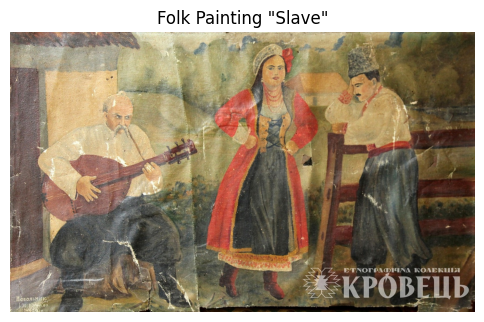

europeana_id       KYD1855
Title              Folk Painting "Slave"
Description        Folk Painting "Slave", Ukraine, Poltavshchyna, Polatava obl., Hadiatskyi rn., v. Mali Budyshcha, Technique: painting, Materials: oil paints, canvas, Creator: Kurylo I. M., mid XX century
Subject            Poltavshchyna - ethnographical region | Category:Ukrainian painting | painting | Canvas
Places             Polatava obl., Hadiatskyi rn., v. Mali Budyshcha
Rights statement   http://creativecommons.org/licenses/by-nc-nd/4.0/


In [5]:
PAINTING = "KYD1855"

def parse_painting_id(s: str) -> str:
    """Return the Europeana id in '1413/KYD1791' form."""
    s = s.strip().rstrip("/")
    m = re.search(r"(\d+)/([A-Za-z0-9_]+)$", s)
    if m:
        return f"{m.group(1)}/{m.group(2)}"
    return f"1413/{s}"   # Krovets collection by default


def fetch_record(eid: str) -> dict:
    """Search API query, same as step_1-01, for a single id."""
    resp = requests.get(
        "https://api.europeana.eu/record/v2/search.json",
        params={"query": f'europeana_id:"/{eid}"', "rows": 1, "profile": "rich"},
        headers=HEADERS, timeout=60,
    )
    resp.raise_for_status()
    items = resp.json().get("items", [])
    if not items:
        raise ValueError(f"No Europeana record found for {eid}")
    return items[0]


def record_to_row(item: dict) -> dict:
    """Flattening logic from step_1-01, unchanged."""
    desc = (item.get('dcDescription') or [''])[0]
    medium_match = re.search(r'Materials:\s*(.*?)(?:,\s*Creator:|$)', desc)
    medium = medium_match.group(1).strip().rstrip(',') if medium_match else ''
    spatial = item.get('dctermsSpatial') or []
    places = [s for s in spatial if isinstance(s, str) and not s.startswith('http')]
    subjects = (item.get('edmConceptPrefLabelLangAware') or {}).get('en', [])
    dates = list(dict.fromkeys((item.get('edmTimespanLabelLangAware') or {}).get('en', [])))
    type_d = item.get('dcTypeLangAware') or {}
    return {
        'europeana_id': (item.get('id', '').split('/')[-1] if item.get('id') else ''),
        'Title': (item.get('title') or [''])[0],
        'Description': desc,
        'ImageLink': (item.get('edmIsShownBy') or [''])[0],
        'Creator': (item.get('dcCreator') or [''])[0],
        'Subject': ' | '.join(subjects),
        'Type of item': (type_d.get('en') or [''])[0],
        'Medium': medium,
        'Providing institution': (item.get('dataProvider') or [''])[0],
        'Aggregator': (item.get('provider') or [''])[0],
        'Rights statement': (item.get('rights') or [''])[0],
        'Creation date': ' | '.join(dates),
        'Places': ' | '.join(places),
        'Identifier': item.get('id', ''),
    }


def load_image_from_url(urls: list[str]) -> Image.Image:
    """Download the first image that works (full image first, Europeana thumbnail as fallback)."""
    for url in urls:
        if not url:
            continue
        try:
            r = requests.get(url, timeout=60, headers={"User-Agent": "AISTER-notebook"})
            r.raise_for_status()
            return Image.open(BytesIO(r.content)).convert("RGB")
        except Exception as e:
            print(f"Could not load {url}: {e}")
    raise RuntimeError("No image could be downloaded for this record.")


EID = parse_painting_id(PAINTING)
record = fetch_record(EID)
row = record_to_row(record)
image = load_image_from_url([row["ImageLink"], (record.get("edmPreview") or [""])[0]])

plt.figure(figsize=(6, 8))
plt.imshow(image)
plt.axis("off")
plt.title(row["Title"])
plt.show()

for k in ("europeana_id", "Title", "Description", "Subject", "Places", "Rights statement"):
    print(f"{k:18s} {row[k]}")

## Step 1 · Reading the text
The first pass uses only the metadata that already exists. **spaCy**, an open-source language library, runs named entity recognition (people, places, works of art), and a few rules handle the way Krovets titles are written: a type, such as *Folk Painting*, followed by a label in quotes that names what is depicted. Tags from the subject terms are added too.

Place names and the creator are recognised but filtered out: the tags are meant to describe what is in the picture, and place and creator already have their own fields in the record.

Text can only find what someone already wrote down, so for most paintings this step yields just a few tags.

In [6]:
SPACY_MODEL = "en_core_web_sm"
NLP = spacy.load(SPACY_MODEL)

MEDIA_PREFIXES = sorted([
    "Professional painting", "Professional icon", "Decorative painting",
    "Folk Painting", "Folk painting", "Folk Icon", "Folk icon",
    "Old Post-card", "Old Post-Card", "Photo", "Sketch",
], key=len, reverse=True)

HUMAN_ROLES = {
    "man", "woman", "boy", "girl", "child", "baby", "infant", "person",
    "mother", "father", "son", "daughter", "elder",
    "men", "women", "boys", "girls", "children", "people",
    "bride", "groom", "couple", "family", "choir",
    "saint", "angel", "apostle", "martyr",
    "kozak", "chumak", "teacher", "priest",
}

FIGURE_STOP = {
    "unknown", "group", "portrait", "group portrait", "family portrait",
    "ukraine", "photo", "photograph",
}
OBJECT_STOP = {
    "painting", "photograph", "photo", "documentary photography",
    "category:ukrainian painting", "ukraine", "ukrainian",
    "technique", "materials", "creator", "unknown",
    "century", "mid", "beginning", "half", "xx century",
    "sewing", "pottery", "printing", "formation",
    "folk", "folk icon", "folk painting", "handmade",
}
SCENE_STOP = {
    "folk painting", "folk icon", "painting", "icon", "folk",
    "photo", "photograph", "old post-card",
}
GEO_LABELS = {"GPE", "LOC", "FAC", "ORG", "DATE", "TIME"}


def dedup(items):
    """Case-insensitive dedup, preserving order."""
    seen, out = set(), []
    for v in items:
        v = v.strip()
        if v and v.lower() not in seen:
            seen.add(v.lower())
            out.append(v)
    return out


def is_place(text, places):
    """True if text matches a known place name."""
    if not text or not places: return False
    low = text.strip().lower()
    return low in places or any(p in low for p in places if len(p) > 3)


def parse_media_title(title):
    """'Folk Icon "St. Michael"' -> ('Folk Icon', 'St. Michael'). Plain titles -> (None, None)."""
    for pfx in MEDIA_PREFIXES:
        if title.startswith(pfx):
            rest = title[len(pfx):].strip()
            m = re.search(r'"([^"]+)"', rest)
            return (pfx, m.group(1).strip()) if m else (pfx, rest or None)
    return None, None


def portrait_of(text):
    """'Portrait of Taras Shevchenko' -> ['Taras Shevchenko']."""
    return [m.group(1).strip().rstrip(".")
            for m in re.finditer(r"[Pp]ortrait\s+of\s+([^\"\\',\n]+)", text)
            if len(m.group(1).strip()) > 1]


def extract_places(row):
    out = set()
    for part in re.split(r"[|,]", str(row.get("Places", "") or "")):
        part = part.strip().lower()
        if not part: continue
        out.add(part)
        for px in ("v.", "rn.", "obl."):
            if part.startswith(px):
                out.add(part[len(px):].strip())
    for tok in str(row.get("Subject", "") or "").split("|"):
        m = re.match(r"(.+?)\s*-\s*ethnograph", tok.strip(), re.I)
        if m: out.add(m.group(1).strip().lower())
    out.discard("")
    return out


def extract_figures(row):
    title   = str(row.get("Title", "") or "").strip()
    desc    = str(row.get("Description", "") or "").strip()
    creator = str(row.get("Creator", "") or "").strip().lower()
    places  = PLACES.get(row.name, set())
    prefix, label = parse_media_title(title)
    span = label or (title if portrait_of(title) else None)
    if not span:
        return []
    figs = portrait_of(span)
    figs += [f"St. {m.group(1)}"
             for m in re.finditer(r"\bSt\.\s*([A-Za-z]+(?:\s+[A-Za-z]+)?)\b", span)]
    words = set(re.findall(r"[a-zA-Z]+", span.lower()))
    figs += [role for role in HUMAN_ROLES if role in words]
    doc = NLP(f"{title} {desc}"[:100_000])
    geo = {(e.start_char, e.end_char) for e in doc.ents if e.label_ in GEO_LABELS}
    for ent in doc.ents:
        if ent.label_ != "PERSON": continue
        if any(ent.start_char < b and ent.end_char > a for a, b in geo): continue
        if ent.text.strip().lower() in span.lower():
            figs.append(ent.text.strip())
    return dedup(f for f in figs
                 if len(f) >= 2 and f.lower() not in FIGURE_STOP
                 and f.lower() != creator and not is_place(f, places))


def extract_objects(row):
    title   = str(row.get("Title", "") or "").strip()
    subject = str(row.get("Subject", "") or "").strip()
    places  = PLACES.get(row.name, set())
    prefix, _ = parse_media_title(title)
    objs = []
    if not prefix and title:
        cleaned = re.sub(r'"[^"]*"', '', title)
        cleaned = re.sub(r'\s{2,}', ' ', cleaned).strip()
        cleaned = re.sub(r'\s+(and|or|with)\s*$', '', cleaned, flags=re.I).strip()
        if cleaned:
            objs.append(cleaned)
    for tok in subject.split("|"):
        tok = tok.strip()
        if tok and ":" not in tok:
            objs.append(tok)
    if subject:
        for ent in NLP(subject[:100_000]).ents:
            if ent.label_ == "PRODUCT":
                objs.append(ent.text.strip())
    return dedup(o for o in objs
                 if len(o) >= 2 and o.lower() not in OBJECT_STOP
                 and not is_place(o, places))


def extract_scenes(row):
    title  = str(row.get("Title", "") or "").strip()
    places = PLACES.get(row.name, set())
    prefix, label = parse_media_title(title)
    scenes = []
    if not prefix:
        if portrait_of(title):
            scenes.append(title)
    else:
        if label:
            scenes.append(label)
        for m in re.finditer(r'"([^"]+)"', title):
            qp = m.group(1).strip()
            if qp != label:
                scenes.append(qp)
        if label:
            for ent in NLP(label[:100_000]).ents:
                if ent.label_ in {"WORK_OF_ART", "EVENT"}:
                    t = ent.text.strip()
                    if t.lower() != label.lower():
                        scenes.append(t)
    META_PFX = ("technique", "materials", "creator")
    return dedup(s for s in scenes
                 if 2 <= len(s) <= 100 and "|" not in s
                 and s.lower() not in SCENE_STOP
                 and not any(s.lower().startswith(kw) for kw in META_PFX)
                 and not is_place(s, places))

In [7]:
df = pd.DataFrame([row])
PLACES = {i: extract_places(r) for i, r in df.iterrows()}
r0 = df.iloc[0]

# 1. Everything spaCy NER finds in the metadata
ner_rows = []
for field, text in [("Title + Description", f"{row['Title']} {row['Description']}"),
                    ("Subject", row["Subject"])]:
    for ent in NLP(text).ents:
        ner_rows.append({"field": field, "entity": ent.text, "label": ent.label_,
                         "meaning": spacy.explain(ent.label_)})

print("Named entities found by spaCy NER:")
if ner_rows:
    display(pd.DataFrame(ner_rows))
else:
    print("  none")

# 2. Candidate tags kept after the rules and filters (as in step_1-02)
text_tags = {
    "figures": extract_figures(r0),
    "objects": extract_objects(r0),
    "scenes":  extract_scenes(r0),
}
print("\nCandidate tags kept:")
for k, v in text_tags.items():
    print(f"  {k:8s} {', '.join(v) if v else '-'}")

# 3. Filtered out: place of origin and creator
places = [p.strip() for p in row["Places"].split("|") if p.strip()]
regions = [t.split(" - ")[0].strip() for t in row["Subject"].split("|") if "ethnograph" in t]
print("\nFiltered out (not depicted in the painting):")
print("  place of origin:", "; ".join(regions + places) or "-")
print("  creator:        ", row["Creator"] or "-")

Named entities found by spaCy NER:


,field,entity,label,meaning
0,Title + Description,Ukraine,GPE,"Countries, cities, states"
1,Title + Description,Poltavshchyna,PERSON,"People, including fictional"
2,Title + Description,Polatava,PERSON,"People, including fictional"
3,Title + Description,Hadiatskyi,PERSON,"People, including fictional"
4,Title + Description,Mali Budyshcha,PERSON,"People, including fictional"
5,Title + Description,Kurylo I. M.,PERSON,"People, including fictional"
6,Title + Description,mid XX century,DATE,Absolute or relative dates or periods
7,Subject,Canvas,ORG,"Companies, agencies, institutions, etc."



Candidate tags kept:
  figures  -
  objects  Canvas
  scenes   Slave

Filtered out (not depicted in the painting):
  place of origin: Poltavshchyna; Polatava obl., Hadiatskyi rn., v. Mali Budyshcha
  creator:         Kurylo I. M.


## Step 2 · Looking at the picture
**Caption.** The vision-language model receives the image with strict instructions: describe only what is clearly visible, do not guess identities, periods or styles, mention figures, objects, setting, visible text and damage, at most 90 words.

In [9]:
def generate_captions(images, max_new_tokens, model, processor):
    messages = [
        [
            {"role": "system", "content": [{"type": "text", "text": CAPTION_PROMPT}]},
            {"role": "user", "content": [
                {"type": "image", "image": img},
                {"type": "text", "text": "Describe only what is clearly visible."},
            ]},
        ]
        for img in images
    ]
    messages = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    device = next(model.parameters()).device
    inputs = processor(text=messages, images=list(images), padding=True,
                       return_tensors="pt").to(device)
    with torch.inference_mode():
        output_ids = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    trimmed = [out[len(inp):] for inp, out in zip(inputs.input_ids, output_ids)]
    generated = processor.batch_decode(trimmed, skip_special_tokens=True,
                                       clean_up_tokenization_spaces=True)
    return [g.strip() for g in generated]


t0 = time.perf_counter()
caption = generate_captions([image], CAPTION_MAX_NEW_TOKENS, vl_model, vl_processor)[0]
print(f"\nCaption ({time.perf_counter() - t0:.1f}s):\n")
print(textwrap.fill(caption, width=100))


Caption (10.0s):

This is a weathered, painted mural depicting three figures in traditional attire. On the left, a man
with a mustache sits playing a large, round-necked string instrument. In the center, a woman stands
with her hands on her hips, wearing a red coat over a dark dress and a patterned head covering. On
the right, a man in a white shirt and dark trousers leans against a wooden fence. The background
shows a rural landscape with trees and a building. The image is visibly damaged with tears and
cracks. Text in the bottom right corner reads "ЕТНОГРАФІЧНА КОЛЕКЦІЯ КРОВЕЦЬ".


**Structured tags.** The text model turns the caption into a fixed JSON template with seven fields: figures, attire, objects, background, scenes, text and damage. It may use only what the caption says. A fixed template makes the output machine-readable and lets a field be switched off if it turns out to be unhelpful; in the pilot, damage tags were rejected most often by participants.

In [10]:
TAG_PROMPT = """
Return one valid JSON object only.

Caption:
<<<CAPTION>>>

Schema:
{
  "figures": [],
  "attire": [],
  "objects": [],
  "background": [],
  "scenes": [],
  "text": [],
  "damage": []
}

Rules:
- Use only information explicitly in the caption.
- Use short noun phrases.
- Do not invent or explain.
- No text before or after the JSON.
- If no items, use [].

Meanings:
- figures = human persons only
- attire = clothing and garment features
- objects = physical non-wearable things
- background = backdrop, surface, environment
- scenes = depiction type or genre
- text = quoted text, watermark, or explicit text-visibility phrase
- damage = damage or condition phrases
"""

TAG_FIELDS = ["figures", "attire", "objects", "background", "scenes", "text", "damage"]


def generate_tags(captions, model, tokenizer):
    messages_batch = [
        [
            {"role": "system", "content": "You are a data extraction AI. Output only valid JSON."},
            {"role": "user", "content": TAG_PROMPT.replace("<<<CAPTION>>>", cap)},
        ]
        for cap in captions
    ]
    texts = [
        tokenizer.apply_chat_template(m, add_generation_prompt=True, tokenize=False) + "{"
        for m in messages_batch
    ]
    inputs = tokenizer(texts, return_tensors="pt", padding=True,
                       truncation=True, max_length=TAG_MAX_INPUT_TOKENS)
    device = next(model.parameters()).device
    inputs = {k: v.to(device) for k, v in inputs.items()}
    prompt_len = inputs["input_ids"].shape[1]
    with torch.inference_mode():
        gen = model.generate(**inputs, max_new_tokens=TAG_MAX_NEW_TOKENS, do_sample=False,
                             eos_token_id=tokenizer.eos_token_id,
                             pad_token_id=tokenizer.pad_token_id)
    results = []
    for i in range(len(captions)):
        decoded = tokenizer.decode(gen[i, prompt_len:], skip_special_tokens=True).strip()
        results.append(_parse_tags("{" + decoded))
    return results


def _parse_tags(text: str) -> dict:
    empty = {k: [] for k in TAG_FIELDS}
    start = text.find("{")
    if start == -1:
        return empty
    depth = 0
    for i in range(start, len(text)):
        if text[i] == "{":
            depth += 1
        elif text[i] == "}":
            depth -= 1
            if depth == 0:
                try:
                    data = json.loads(text[start:i + 1])
                    return {k: data.get(k, []) if isinstance(data.get(k), list) else [] for k in TAG_FIELDS}
                except json.JSONDecodeError:
                    return empty
    return empty


if tag_model is None:   # not enough GPU memory for both models: swap them
    del vl_model
    torch.cuda.empty_cache()
    tag_model, tag_tokenizer = load_tag_model()

t0 = time.perf_counter()
image_tags = generate_tags([caption], tag_model, tag_tokenizer)[0]
print(f"Tags ({time.perf_counter() - t0:.1f}s):\n")
print(json.dumps(image_tags, indent=2, ensure_ascii=False))

Tags (31.2s):

{
  "figures": [
    "man with mustache",
    "woman",
    "man"
  ],
  "attire": [
    "traditional attire",
    "red coat",
    "dark dress",
    "patterned head covering",
    "white shirt",
    "dark trousers"
  ],
  "objects": [
    "large round-necked string instrument",
    "wooden fence"
  ],
  "background": [
    "rural landscape",
    "trees",
    "building"
  ],
  "scenes": [
    "weathered painted mural"
  ],
  "text": [
    "ЕТНОГРАФІЧНА КОЛЕКЦІЯ КРОВЕЦЬ"
  ],
  "damage": [
    "tears",
    "cracks"
  ]
}


## Step 3 · People decide
**W3C Web Annotations.** Text and image tags are merged and de-duplicated, and each tag becomes a W3C Web Annotation in JSON-LD: the tag (*body*), the Europeana object it describes (*target*) and who made it (*creator*). This standard format is what CrowdHeritage imports, and what it exports again once people have voted.

In [14]:
JSONLD_CONTEXT = {
    "as": "https://www.w3.org/ns/activitystreams#", "dc": "http://purl.org/dc/terms/",
    "dce": "http://purl.org/dc/elements/1.1/", "foaf": "http://xmlns.com/foaf/0.1/",
    "oa": "http://www.w3.org/ns/oa#", "rdf": "http://www.w3.org/1999/02/22-rdf-syntax-ns#",
    "xsd": "http://www.w3.org/2001/XMLSchema#", "soa": "http://sw.islab.ntua.gr/annotation/",
    "id": {"@id": "@id", "@type": "@id"}, "type": {"@id": "@type", "@type": "@id"},
    "value": "rdf:value", "created": {"@id": "dc:created", "@type": "xsd:dateTime"},
    "creator": {"@id": "dc:creator", "@type": "@id"}, "language": "dc:language",
    "Software": "as:Application", "name": "foaf:name", "Annotation": "oa:Annotation",
    "TextPositionSelector": "oa:TextPositionSelector", "TextualBody": "oa:TextualBody",
    "body": {"@id": "oa:hasBody", "@type": "@id"}, "scope": {"@id": "oa:hasScope", "@type": "@id"},
    "selector": {"@id": "oa:hasSelector", "@type": "@id"}, "source": {"@id": "oa:hasSource", "@type": "@id"},
    "target": {"@id": "oa:hasTarget", "@type": "@id"}, "Literal": "soa:Literal",
}

all_tags = dedup(
    [t for v in text_tags.values() for t in v]
    + [t for k in TAG_FIELDS for t in image_tags.get(k, []) if isinstance(t, str)]
)

now = datetime.now(timezone.utc).strftime("%a %b %d %H:%M:%S UTC %Y")
annotations = {
    "@context": JSONLD_CONTEXT,
    "@graph": [
        {
            "type": "Annotation",
            "created": now,
            "creator": {"id": "_", "name": f"{VL_MODEL_NAME.split('/')[-1]}, {TAG_MODEL_NAME.split('/')[-1]}", "type": "Software"},
            "confidence": 0.5,
            "body": {"type": "TextualBody", "value": tag, "language": "en"},
            "target": {"source": f"/{EID}"},
            "scope": "dc:subject",
        }
        for tag in all_tags
    ],
}

print(f"{len(all_tags)} candidate tags: " + ", ".join(all_tags))
print("\nOne of them as a Web Annotation:\n")
first_image_tag = next((t for k in TAG_FIELDS for t in image_tags.get(k, []) if isinstance(t, str)), None)
example = next((a for a in annotations["@graph"] if a["body"]["value"] == first_image_tag),
               annotations["@graph"][0])
print(json.dumps(example, indent=2, ensure_ascii=False))

20 candidate tags: Canvas, Slave, man with mustache, woman, man, traditional attire, red coat, dark dress, patterned head covering, white shirt, dark trousers, large round-necked string instrument, wooden fence, rural landscape, trees, building, weathered painted mural, ЕТНОГРАФІЧНА КОЛЕКЦІЯ КРОВЕЦЬ, tears, cracks

One of them as a Web Annotation:

{
  "type": "Annotation",
  "created": "Fri Nov 06 09:38:32 UTC 2026",
  "creator": {
    "id": "_",
    "name": "Qwen3-VL-2B-Instruct, Qwen3.5-4B",
    "type": "Software"
  },
  "confidence": 0.5,
  "body": {
    "type": "TextualBody",
    "value": "man with mustache",
    "language": "en"
  },
  "target": {
    "source": "/1413/KYD1855"
  },
  "scope": "dc:subject"
}


**What the crowd decided.** In the pilot, 70 contributors reviewed these suggestions on [CrowdHeritage](https://crowdheritage.eu) during five workshops in March–April 2026: voting a tag up if it was right, down if it was wrong, and adding tags of their own. A tag is accepted when it has more up than down votes, rejected with more down votes, undecided on a tie. The table shows the pilot's final result for this painting, read from the published dataset (votes summed over all workshops). *Proposed today* marks the tags that this run suggested as well.

In [12]:
final = pd.read_excel(PILOT_FINAL)
votes = pd.read_csv(PILOT_VOTES)

crowd = final[final["europeana_id"].astype(str) == row["europeana_id"]].copy()
if crowd.empty:
    print("This painting is not in the pilot's final dataset.")
else:
    origin = (votes[votes["europeana_id"].astype(str) == row["europeana_id"]]
              .assign(key=lambda d: d["tag"].str.lower())
              .groupby("key")["type"].first())
    # terms revised after the DE-BIAS check keep the origin of the original tag
    REVISED = {"enslaved person": "slave"}
    original = crowd["value"].str.lower().map(lambda v: REVISED.get(v, v))
    crowd["source"] = original.map(origin).map({"Software": "AI", "User": "person"}).fillna("")
    crowd.loc[original != crowd["value"].str.lower(), "source"] += " (revised in step 4)"
    today = {t.lower() for t in all_tags}
    crowd["proposed today"] = original.isin(today).map({True: "yes", False: ""})
    crowd = crowd.sort_values(["recommendation", "upvotes"], ascending=[True, False])
    display(crowd[["value", "source", "upvotes", "downvotes", "recommendation", "proposed today"]]
            .reset_index(drop=True))

,value,source,upvotes,downvotes,recommendation,proposed today
0,"large, round-necked string instrument",AI,10,0,accept,
1,woman,AI,10,0,accept,yes
2,older man,AI,10,0,accept,
3,man,AI,10,0,accept,yes
4,traditional attire,AI,9,0,accept,yes
5,"weathered, painted artwork",AI,9,0,accept,
6,red coat,AI,9,1,accept,yes
7,dark trousers,AI,8,1,accept,yes
8,wooden fence,AI,8,1,accept,yes
9,white shirt,AI,8,1,accept,yes


## Step 4 · Checking the words
A majority vote says whether a tag is accurate, not whether it is appropriate. The final step screens the tags against the vocabulary of the **DE-BIAS** project, which lists contentious terms in heritage descriptions, with explanations and suggested alternatives. Tags are normalised (case, accents, punctuation) and compared with the English terms that DE-BIAS marks as contentious in any context; terms it marks as ambiguous, harmful only in some contexts, are left out to avoid false alarms.

In the pilot this check found one term across 5,946 annotations: *slave*, from the title of painting KYD1855, accepted by participants and then replaced with *enslaved person* as the vocabulary recommends.

In [13]:
def norm(s: str) -> str:
    s = unicodedata.normalize('NFKC', s).casefold().strip()
    s = re.sub(r'[^\w\s-]', ' ', s, flags=re.UNICODE)
    s = re.sub(r'\s+', ' ', s).strip()
    return s


rdf_bytes = requests.get(DEBIAS_RDF, timeout=120).content
root = ET.fromstring(rdf_bytes)
rdf = '{http://www.w3.org/1999/02/22-rdf-syntax-ns#}'
lang_key = '{http://www.w3.org/XML/1998/namespace}lang'

terms = {
    norm(literal.text)
    for desc in root.findall(f'{rdf}Description')
    if any(c.tag.endswith('hasContentiousIssue') for c in desc)
    for literal in [next((c for c in desc if c.tag.endswith('literalForm') and (c.text or '').strip()), None)]
    for ambiguous in [next((c for c in desc if c.tag.endswith('isAmbiguous')), None)]
    if (
        literal is not None
        and literal.attrib.get(lang_key) == 'en'
        and ambiguous is not None
        and (ambiguous.text or '').strip().lower() == 'false'
    )
}
print(f"{len(terms)} English contentious terms")


def debias_check(tags):
    return [t for t in tags if norm(t) in terms]


to_check = list(all_tags) + (crowd["value"].tolist() if not crowd.empty else [])
hits = debias_check(dedup(to_check))
print(f"Checked {len(dedup(to_check))} tags for {row['europeana_id']}.")
print("Flagged:", ", ".join(hits) if hits else "none")

139 English contentious terms
Checked 25 tags for KYD1855.
Flagged: Slave
